# Home Loan Default Risk Analysis and Prediction

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score
from sklearn.metrics import confusion_matrix, classification_report
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)

## 2. Set dataset file paths

In [2]:
from pathlib import Path

data_path = Path("Data")

application_file = data_path / "application_train.csv"
bureau_file = data_path / "bureau.csv"
bureau_balance_file = data_path / "bureau_balance.csv"
pos_cash_file = data_path / "POS_CASH_balance.csv"
credit_card_file = data_path / "credit_card_balance.csv"
previous_application_file = data_path / "previous_application.csv"
installments_file = data_path / "installments_payments.csv"

files = [
    application_file,
    bureau_file,
    bureau_balance_file,
    pos_cash_file,
    credit_card_file,
    previous_application_file,
    installments_file
]

for file in files:
    print(file, file.exists())

Data/application_train.csv True
Data/bureau.csv True
Data/bureau_balance.csv True
Data/POS_CASH_balance.csv True
Data/credit_card_balance.csv True
Data/previous_application.csv True
Data/installments_payments.csv True


## 3. Load and understand the main application dataset

In [3]:
application = pd.read_csv(application_file)

print("Dataset shape:", application.shape)

print(application.head())

Dataset shape: (307511, 122)
   SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR  \
0      100002       1         Cash loans           M            N   
1      100003       0         Cash loans           F            N   
2      100004       0    Revolving loans           M            Y   
3      100006       0         Cash loans           F            N   
4      100007       0         Cash loans           M            N   

  FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
0               Y             0          202500.0    406597.5      24700.5   
1               N             0          270000.0   1293502.5      35698.5   
2               Y             0           67500.0    135000.0       6750.0   
3               Y             0          135000.0    312682.5      29686.5   
4               Y             0          121500.0    513000.0      21865.5   

   AMT_GOODS_PRICE NAME_TYPE_SUITE NAME_INCOME_TYPE  \
0         351000.0   Unaccompani

In [4]:
application.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [5]:
print(application["TARGET"].value_counts())
print(application["TARGET"].value_counts(normalize=True) * 100)

TARGET
0    282686
1     24825
Name: count, dtype: int64
TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


## 4. Exploratory data analysis

In [6]:
print(application.isnull().sum().sort_values(ascending=False).head(20))

COMMONAREA_MEDI             214865
COMMONAREA_AVG              214865
COMMONAREA_MODE             214865
NONLIVINGAPARTMENTS_MODE    213514
NONLIVINGAPARTMENTS_AVG     213514
NONLIVINGAPARTMENTS_MEDI    213514
FONDKAPREMONT_MODE          210295
LIVINGAPARTMENTS_MODE       210199
LIVINGAPARTMENTS_AVG        210199
LIVINGAPARTMENTS_MEDI       210199
FLOORSMIN_AVG               208642
FLOORSMIN_MODE              208642
FLOORSMIN_MEDI              208642
YEARS_BUILD_MEDI            204488
YEARS_BUILD_MODE            204488
YEARS_BUILD_AVG             204488
OWN_CAR_AGE                 202929
LANDAREA_MEDI               182590
LANDAREA_MODE               182590
LANDAREA_AVG                182590
dtype: int64


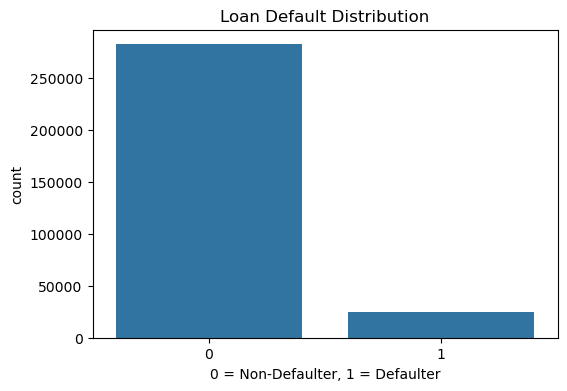

In [7]:
plt.figure(figsize=(6, 4))
sns.countplot(data=application, x="TARGET")
plt.title("Loan Default Distribution")
plt.xlabel("0 = Non-Defaulter, 1 = Defaulter")
plt.show()

In [8]:
print(application.select_dtypes(include=np.number).describe().T.head(20))

                               count           mean            std  \
SK_ID_CURR                  307511.0  278180.518577  102790.175348   
TARGET                      307511.0       0.080729       0.272419   
CNT_CHILDREN                307511.0       0.417052       0.722121   
AMT_INCOME_TOTAL            307511.0  168797.919297  237123.146279   
AMT_CREDIT                  307511.0  599025.999706  402490.776996   
AMT_ANNUITY                 307499.0   27108.573909   14493.737315   
AMT_GOODS_PRICE             307233.0  538396.207429  369446.460540   
REGION_POPULATION_RELATIVE  307511.0       0.020868       0.013831   
DAYS_BIRTH                  307511.0  -16036.995067    4363.988632   
DAYS_EMPLOYED               307511.0   63815.045904  141275.766519   
DAYS_REGISTRATION           307511.0   -4986.120328    3522.886321   
DAYS_ID_PUBLISH             307511.0   -2994.202373    1509.450419   
OWN_CAR_AGE                 104582.0      12.061091      11.944812   
FLAG_MOBIL          

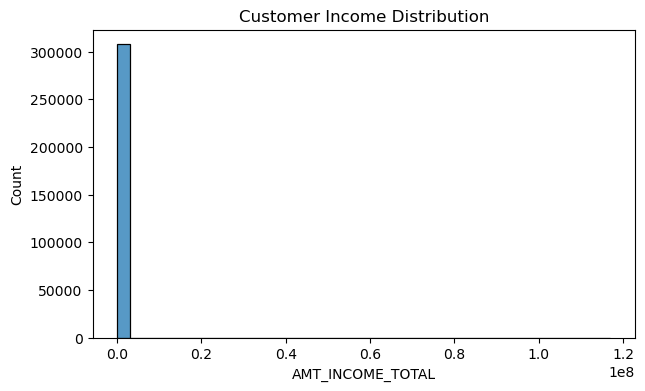

In [9]:
plt.figure(figsize=(7, 4))
sns.histplot(application["AMT_INCOME_TOTAL"], bins=40)
plt.title("Customer Income Distribution")
plt.show()

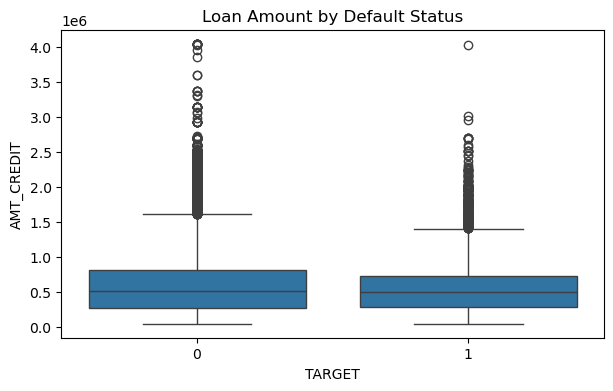

In [10]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=application, x="TARGET", y="AMT_CREDIT")
plt.title("Loan Amount by Default Status")
plt.show()

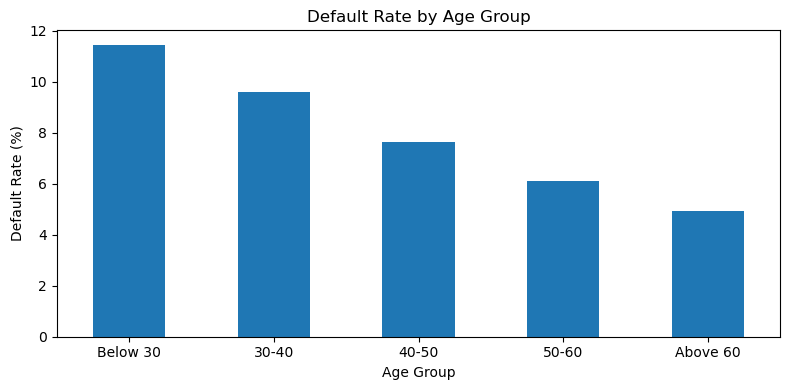

Default Rate by Age Group:
AGE_GROUP
Below 30    11.44
30-40        9.59
40-50        7.64
50-60        6.12
Above 60     4.92
Name: TARGET, dtype: float64


In [11]:
application["AGE_GROUP"] = pd.cut(
    -application["DAYS_BIRTH"] / 365.25,
    bins=[0, 30, 40, 50, 60, 100],
    labels=["Below 30", "30-40", "40-50", "50-60", "Above 60"]
)

age_default = application.groupby(
    "AGE_GROUP", observed=False
)["TARGET"].mean() * 100

plt.figure(figsize=(8, 4))
age_default.plot(kind="bar")

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Default Rate by Age Group:")
print(age_default.round(2))

## 5. Prepare the main application dataset

In [12]:
application["DAYS_EMPLOYED"] = application["DAYS_EMPLOYED"].replace(365243, np.nan)
application["AGE_YEARS"] = -application["DAYS_BIRTH"] / 365.25
application["EMPLOYMENT_YEARS"] = -application["DAYS_EMPLOYED"] / 365.25
application["CREDIT_INCOME_RATIO"] = application["AMT_CREDIT"] / application["AMT_INCOME_TOTAL"].replace(0, np.nan)
application["ANNUITY_INCOME_RATIO"] = application["AMT_ANNUITY"] / application["AMT_INCOME_TOTAL"].replace(0, np.nan)
application["CREDIT_ANNUITY_RATIO"] = application["AMT_CREDIT"] / application["AMT_ANNUITY"].replace(0, np.nan)
display(application[["AGE_YEARS", "EMPLOYMENT_YEARS", "CREDIT_INCOME_RATIO", "ANNUITY_INCOME_RATIO", "CREDIT_ANNUITY_RATIO", "TARGET"]].head())

,AGE_YEARS,EMPLOYMENT_YEARS,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_ANNUITY_RATIO,TARGET
0,25.902806,1.744011,2.007889,0.121978,16.461104,1
1,45.900068,3.252567,4.790750,0.132217,36.234085,0
2,52.145106,0.616016,2.000000,0.100000,20.000000,0
3,52.032854,8.320329,2.316167,0.219900,10.532818,0
4,54.570842,8.317591,4.222222,0.179963,23.461618,0


## 6. Create features from bureau.csv

In [13]:
bureau = pd.read_csv(bureau_file, usecols=[
    "SK_ID_CURR", "SK_ID_BUREAU", "CREDIT_ACTIVE", "DAYS_CREDIT",
    "CREDIT_DAY_OVERDUE", "AMT_CREDIT_SUM", "AMT_CREDIT_SUM_DEBT",
    "AMT_CREDIT_SUM_OVERDUE"
])
bureau_features = bureau.groupby("SK_ID_CURR").agg(
    BUREAU_LOAN_COUNT=("SK_ID_BUREAU", "count"),
    BUREAU_DAYS_CREDIT_MEAN=("DAYS_CREDIT", "mean"),
    BUREAU_OVERDUE_DAYS_MAX=("CREDIT_DAY_OVERDUE", "max"),
    BUREAU_CREDIT_SUM_MEAN=("AMT_CREDIT_SUM", "mean"),
    BUREAU_DEBT_MEAN=("AMT_CREDIT_SUM_DEBT", "mean"),
    BUREAU_OVERDUE_AMOUNT_MAX=("AMT_CREDIT_SUM_OVERDUE", "max")
).reset_index()
display(bureau_features.head())

,SK_ID_CURR,BUREAU_LOAN_COUNT,BUREAU_DAYS_CREDIT_MEAN,BUREAU_OVERDUE_DAYS_MAX,BUREAU_CREDIT_SUM_MEAN,BUREAU_DEBT_MEAN,BUREAU_OVERDUE_AMOUNT_MAX
0,100001,7,-735.000000,0,207623.571429,85240.928571,0.0
1,100002,8,-874.000000,0,108131.945625,49156.200000,0.0
2,100003,4,-1400.750000,0,254350.125000,0.000000,0.0
3,100004,2,-867.000000,0,94518.900000,0.000000,0.0
4,100005,3,-190.666667,0,219042.000000,189469.500000,0.0


In [14]:
bureau_status = pd.crosstab(bureau["SK_ID_CURR"], bureau["CREDIT_ACTIVE"])
bureau_status.columns = ["BUREAU_STATUS_" + str(c) for c in bureau_status.columns]
bureau_features = bureau_features.merge(bureau_status.reset_index(), on="SK_ID_CURR", how="left")
display(bureau_features.head())

,SK_ID_CURR,BUREAU_LOAN_COUNT,BUREAU_DAYS_CREDIT_MEAN,BUREAU_OVERDUE_DAYS_MAX,BUREAU_CREDIT_SUM_MEAN,BUREAU_DEBT_MEAN,BUREAU_OVERDUE_AMOUNT_MAX,BUREAU_STATUS_Active,BUREAU_STATUS_Bad debt,BUREAU_STATUS_Closed,BUREAU_STATUS_Sold
0,100001,7,-735.000000,0,207623.571429,85240.928571,0.0,3,0,4,0
1,100002,8,-874.000000,0,108131.945625,49156.200000,0.0,2,0,6,0
2,100003,4,-1400.750000,0,254350.125000,0.000000,0.0,1,0,3,0
3,100004,2,-867.000000,0,94518.900000,0.000000,0.0,0,0,2,0
4,100005,3,-190.666667,0,219042.000000,189469.500000,0.0,2,0,1,0


## 7. Create features from bureau_balance.csv

In [15]:
bureau_balance = pd.read_csv(bureau_balance_file, usecols=["SK_ID_BUREAU", "MONTHS_BALANCE", "STATUS"])
bureau_balance = bureau_balance.merge(
    bureau[["SK_ID_BUREAU", "SK_ID_CURR"]].drop_duplicates(),
    on="SK_ID_BUREAU", how="left"
)
bureau_balance["STATUS_NUMBER"] = pd.to_numeric(bureau_balance["STATUS"], errors="coerce")
bureau_balance_features = bureau_balance.groupby("SK_ID_CURR").agg(
    BUREAU_BALANCE_MONTHS=("MONTHS_BALANCE", "count"),
    BUREAU_BALANCE_STATUS_MEAN=("STATUS_NUMBER", "mean"),
    BUREAU_BALANCE_STATUS_MAX=("STATUS_NUMBER", "max")
).reset_index()
display(bureau_balance_features.head())

,SK_ID_CURR,BUREAU_BALANCE_MONTHS,BUREAU_BALANCE_STATUS_MEAN,BUREAU_BALANCE_STATUS_MAX
0,100001.0,172,0.031250,1.0
1,100002.0,110,0.375000,1.0
2,100005.0,21,0.000000,0.0
3,100010.0,72,0.000000,0.0
4,100013.0,230,0.081395,1.0


## 8. Create features from previous_application.csv

In [16]:
previous = pd.read_csv(previous_application_file, usecols=[
    "SK_ID_CURR", "SK_ID_PREV", "AMT_APPLICATION", "AMT_CREDIT",
    "AMT_ANNUITY", "DAYS_DECISION", "NAME_CONTRACT_STATUS"
])
previous_features = previous.groupby("SK_ID_CURR").agg(
    PREVIOUS_APPLICATION_COUNT=("SK_ID_PREV", "count"),
    PREVIOUS_CREDIT_MEAN=("AMT_CREDIT", "mean"),
    PREVIOUS_APPLICATION_AMOUNT_MEAN=("AMT_APPLICATION", "mean"),
    PREVIOUS_ANNUITY_MEAN=("AMT_ANNUITY", "mean"),
    PREVIOUS_DECISION_DAYS_MEAN=("DAYS_DECISION", "mean")
).reset_index()
display(previous_features.head())

,SK_ID_CURR,PREVIOUS_APPLICATION_COUNT,PREVIOUS_CREDIT_MEAN,PREVIOUS_APPLICATION_AMOUNT_MEAN,PREVIOUS_ANNUITY_MEAN,PREVIOUS_DECISION_DAYS_MEAN
0,100001,1,23787.00,24835.50,3951.000,-1740.0
1,100002,1,179055.00,179055.00,9251.775,-606.0
2,100003,3,484191.00,435436.50,56553.990,-1305.0
3,100004,1,20106.00,24282.00,5357.250,-815.0
4,100005,2,20076.75,22308.75,4813.200,-536.0


In [17]:
previous_status = pd.crosstab(previous["SK_ID_CURR"], previous["NAME_CONTRACT_STATUS"])
previous_status.columns = ["PREVIOUS_STATUS_" + str(c) for c in previous_status.columns]
previous_features = previous_features.merge(previous_status.reset_index(), on="SK_ID_CURR", how="left")
display(previous_features.head())

,SK_ID_CURR,PREVIOUS_APPLICATION_COUNT,PREVIOUS_CREDIT_MEAN,PREVIOUS_APPLICATION_AMOUNT_MEAN,PREVIOUS_ANNUITY_MEAN,PREVIOUS_DECISION_DAYS_MEAN,PREVIOUS_STATUS_Approved,PREVIOUS_STATUS_Canceled,PREVIOUS_STATUS_Refused,PREVIOUS_STATUS_Unused offer
0,100001,1,23787.00,24835.50,3951.000,-1740.0,1,0,0,0
1,100002,1,179055.00,179055.00,9251.775,-606.0,1,0,0,0
2,100003,3,484191.00,435436.50,56553.990,-1305.0,3,0,0,0
3,100004,1,20106.00,24282.00,5357.250,-815.0,1,0,0,0
4,100005,2,20076.75,22308.75,4813.200,-536.0,1,1,0,0


## 9. Create features from installments_payments.csv

In [18]:
installments = pd.read_csv(installments_file, usecols=[
    "SK_ID_PREV", "DAYS_INSTALMENT", "DAYS_ENTRY_PAYMENT",
    "AMT_INSTALMENT", "AMT_PAYMENT"
])
installments = installments.merge(
    previous[["SK_ID_PREV", "SK_ID_CURR"]].drop_duplicates(),
    on="SK_ID_PREV", how="left"
)
installments["PAYMENT_DELAY"] = installments["DAYS_ENTRY_PAYMENT"] - installments["DAYS_INSTALMENT"]
installments["PAYMENT_DIFFERENCE"] = installments["AMT_PAYMENT"] - installments["AMT_INSTALMENT"]
installments["LATE_PAYMENT"] = (installments["PAYMENT_DELAY"] > 0).astype(int)
installment_features = installments.groupby("SK_ID_CURR").agg(
    PAYMENT_DELAY_MEAN=("PAYMENT_DELAY", "mean"),
    PAYMENT_DELAY_MAX=("PAYMENT_DELAY", "max"),
    PAYMENT_DIFFERENCE_MEAN=("PAYMENT_DIFFERENCE", "mean"),
    LATE_PAYMENT_COUNT=("LATE_PAYMENT", "sum"),
    INSTALLMENT_COUNT=("AMT_INSTALMENT", "count")
).reset_index()
display(installment_features.head())

,SK_ID_CURR,PAYMENT_DELAY_MEAN,PAYMENT_DELAY_MAX,PAYMENT_DIFFERENCE_MEAN,LATE_PAYMENT_COUNT,INSTALLMENT_COUNT
0,100001.0,-15.500000,-6.0,0.0,0,4
1,100002.0,-20.421053,-12.0,0.0,0,19
2,100003.0,-7.160000,-1.0,0.0,0,25
3,100004.0,-7.666667,-3.0,0.0,0,3
4,100005.0,-23.555556,1.0,0.0,1,9


## 10. Create features from POS_CASH_balance.csv

In [19]:
pos_cash = pd.read_csv(pos_cash_file, usecols=[
    "SK_ID_PREV", "MONTHS_BALANCE", "CNT_INSTALMENT_FUTURE",
    "SK_DPD", "SK_DPD_DEF"
])
pos_cash = pos_cash.merge(
    previous[["SK_ID_PREV", "SK_ID_CURR"]].drop_duplicates(),
    on="SK_ID_PREV", how="left"
)
pos_features = pos_cash.groupby("SK_ID_CURR").agg(
    POS_RECORD_COUNT=("MONTHS_BALANCE", "count"),
    POS_INSTALLMENT_FUTURE_MEAN=("CNT_INSTALMENT_FUTURE", "mean"),
    POS_DPD_MEAN=("SK_DPD", "mean"),
    POS_DPD_MAX=("SK_DPD", "max"),
    POS_DPD_DEF_MAX=("SK_DPD_DEF", "max")
).reset_index()
display(pos_features.head())

,SK_ID_CURR,POS_RECORD_COUNT,POS_INSTALLMENT_FUTURE_MEAN,POS_DPD_MEAN,POS_DPD_MAX,POS_DPD_DEF_MAX
0,100001.0,5,2.000000,0.0,0,0
1,100002.0,19,15.000000,0.0,0,0
2,100003.0,28,5.785714,0.0,0,0
3,100004.0,4,2.250000,0.0,0,0
4,100005.0,11,7.200000,0.0,0,0


## 11. Create features from credit_card_balance.csv

In [20]:
credit_card = pd.read_csv(credit_card_file, usecols=[
    "SK_ID_PREV", "MONTHS_BALANCE", "AMT_BALANCE",
    "AMT_CREDIT_LIMIT_ACTUAL", "AMT_DRAWINGS_CURRENT",
    "SK_DPD", "SK_DPD_DEF"
])
credit_card = credit_card.merge(
    previous[["SK_ID_PREV", "SK_ID_CURR"]].drop_duplicates(),
    on="SK_ID_PREV", how="left"
)
credit_card["CREDIT_UTILIZATION"] = (
    credit_card["AMT_BALANCE"] / credit_card["AMT_CREDIT_LIMIT_ACTUAL"].replace(0, np.nan)
)
credit_card_features = credit_card.groupby("SK_ID_CURR").agg(
    CREDIT_CARD_RECORD_COUNT=("MONTHS_BALANCE", "count"),
    CREDIT_CARD_BALANCE_MEAN=("AMT_BALANCE", "mean"),
    CREDIT_CARD_UTILIZATION_MEAN=("CREDIT_UTILIZATION", "mean"),
    CREDIT_CARD_DRAWINGS_MEAN=("AMT_DRAWINGS_CURRENT", "mean"),
    CREDIT_CARD_DPD_MAX=("SK_DPD", "max"),
    CREDIT_CARD_DPD_DEF_MAX=("SK_DPD_DEF", "max")
).reset_index()
display(credit_card_features.head())

,SK_ID_CURR,CREDIT_CARD_RECORD_COUNT,CREDIT_CARD_BALANCE_MEAN,CREDIT_CARD_UTILIZATION_MEAN,CREDIT_CARD_DRAWINGS_MEAN,CREDIT_CARD_DPD_MAX,CREDIT_CARD_DPD_DEF_MAX
0,100006.0,6,0.000000,0.000000,0.000000,0,0
1,100011.0,74,54482.111149,0.302678,2432.432432,0,0
2,100021.0,17,0.000000,0.000000,0.000000,0,0
3,100023.0,8,0.000000,0.000000,0.000000,0,0
4,100028.0,49,8085.058163,0.035934,6156.400408,0,0


## 12. Combine all customer-level features

In [21]:
final_data = application.copy()
feature_tables = [
    bureau_features, bureau_balance_features, previous_features,
    installment_features, pos_features, credit_card_features
]
for table in feature_tables:
    final_data = final_data.merge(table, on="SK_ID_CURR", how="left")
print("Final dataset shape:", final_data.shape)
print("Unique application IDs:", final_data["SK_ID_CURR"].nunique())
print("Number of rows:", len(final_data))
display(final_data.head())

Final dataset shape: (307511, 166)
Unique application IDs: 307511
Number of rows: 307511


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR,AGE_GROUP,AGE_YEARS,EMPLOYMENT_YEARS,CREDIT_INCOME_RATIO,ANNUITY_INCOME_RATIO,CREDIT_ANNUITY_RATIO,BUREAU_LOAN_COUNT,BUREAU_DAYS_CREDIT_MEAN,BUREAU_OVERDUE_DAYS_MAX,BUREAU_CREDIT_SUM_MEAN,BUREAU_DEBT_MEAN,BUREAU_OVERDUE_AMOUNT_MAX,BUREAU_STATUS_Active,BUREAU_STATUS_Bad debt,BUREAU_STATUS_Closed,BUREAU_STATUS_Sold,BUREAU_BALANCE_MONTHS,BUREAU_BALANCE_STATUS_MEAN,BUREAU_BALANCE_STATUS_MAX,PREVIOUS_APPLICATION_COUNT,PREVIOUS_CREDIT_MEAN,PREVIOUS_APPLICATION_AMOUNT_MEAN,PREVIOUS_ANNUITY_MEAN,PREVIOUS_DECISION_DAYS_MEAN,PREVIOUS_STATUS_Approved,PREVIOUS_STATUS_Canceled,PREVIOUS_STATUS_Refused,PREVIOUS_STATUS_Unused offer,PAYMENT_DELAY_MEAN,PAYMENT_DELAY_MAX,PAYMENT_DIFFERENCE_MEAN,LATE_PAYMENT_COUNT,INSTALLMENT_COUNT,POS_RECORD_COUNT,POS_INSTALLMENT_FUTURE_MEAN,POS_DPD_MEAN,POS_DPD_MAX,POS_DPD_DEF_MAX,CREDIT_CARD_RECORD_COUNT,CREDIT_CARD_BALANCE_MEAN,CREDIT_CARD_UTILIZATION_MEAN,CREDIT_CARD_DRAWINGS_MEAN,CREDIT_CARD_DPD_MAX,CREDIT_CARD_DPD_DEF_MAX
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637.0,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,...,0.0,0.0,0.0,0.0,0.0,1.0,Below 30,25.902806,1.744011,2.007889,0.121978,16.461104,8.0,-874.00,0.0,108131.945625,49156.2,0.0,2.0,0.0,6.0,0.0,110.0,0.375,1.0,1.0,179055.00,179055.00,9251.775,-606.000000,1.0,0.0,0.0,0.0,-20.421053,-12.0,0.000000,0.0,19.0,19.0,15.000000,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188.0,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,...,0.0,0.0,0.0,0.0,0.0,0.0,40-50,45.900068,3.252567,4.790750,0.132217,36.234085,4.0,-1400.75,0.0,254350.125000,0.0,0.0,1.0,0.0,3.0,0.0,NaN,NaN,NaN,3.0,484191.00,435436.50,56553.990,-1305.000000,3.0,0.0,0.0,0.0,-7.160000,-1.0,0.000000,0.0,25.0,28.0,5.785714,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225.0,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,50-60,52.145106,0.616016,2.000000,0.100000,20.000000,2.0,-867.00,0.0,94518.900000,0.0,0.0,0.0,0.0,2.0,0.0,NaN,NaN,NaN,1.0,20106.00,24282.00,5357.250,-815.000000,1.0,0.0,0.0,0.0,-7.666667,-3.0,0.000000,0.0,3.0,4.0,2.250000,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039.0,-9833.0,-2437,Na

In [22]:
final_data = final_data.replace([np.inf, -np.inf], np.nan)
print("Duplicate application IDs:", final_data["SK_ID_CURR"].duplicated().sum())
print("Total missing values:", final_data.isnull().sum().sum())

Duplicate application IDs: 0
Total missing values: 12081527


## 13. Prepare data for machine learning

In [23]:
X = final_data.drop(columns=["TARGET", "SK_ID_CURR"])
y = final_data["TARGET"]
X = pd.get_dummies(X, dummy_na=True, dtype=int)
X = X.replace([np.inf, -np.inf], np.nan)
print("Feature matrix:", X.shape)
print("Target:", y.shape)

Feature matrix: (307511, 309)
Target: (307511,)


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
X_test_original = X_test.copy()
print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 246008
Testing rows: 61503


In [25]:
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data ready:", X_train.shape)
print("Testing data ready:", X_test.shape)

print("Feature scaling completed")


Training data ready: (246008, 309)
Testing data ready: (61503, 309)
Feature scaling completed


## 14. Train machine-learning algorithms

### Logistic Regression

In [ ]:
logistic_model = LogisticRegression(
    max_iter=500,
    class_weight="balanced",
    solver="liblinear",
    random_state=42
)

# Train using scaled data
logistic_model.fit(X_train_scaled, y_train)

logistic_predictions = logistic_model.predict(X_test_scaled)

logistic_probabilities = logistic_model.predict_proba(
    X_test_scaled
)[:, 1]

print("Logistic Regression training completed")


### Decision Tree

In [ ]:
decision_tree_model = DecisionTreeClassifier(
    max_depth=8, class_weight="balanced", random_state=42
)
decision_tree_model.fit(X_train, y_train)
tree_predictions = decision_tree_model.predict(X_test)
tree_probabilities = decision_tree_model.predict_proba(X_test)[:, 1]

### Random Forest

In [ ]:
random_forest_model = RandomForestClassifier(
    n_estimators=100, max_depth=12, min_samples_leaf=5,
    class_weight="balanced", random_state=42, n_jobs=-1
)
random_forest_model.fit(X_train, y_train)
forest_predictions = random_forest_model.predict(X_test)
forest_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

## 15. Compare model performance

In [ ]:
def model_results(name, actual, predicted, probabilities):
    return {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1 Score": f1_score(actual, predicted, zero_division=0),
        "ROC AUC": roc_auc_score(actual, probabilities),
        "PR AUC": average_precision_score(actual, probabilities)
    }

results = pd.DataFrame([
    model_results("Logistic Regression", y_test, logistic_predictions, logistic_probabilities),
    model_results("Decision Tree", y_test, tree_predictions, tree_probabilities),
    model_results("Random Forest", y_test, forest_predictions, forest_probabilities)
]).sort_values("PR AUC", ascending=False)
display(results)

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(data=results, x="Model", y="PR AUC")
plt.title("Model Comparison Using PR AUC")
plt.xticks(rotation=15)
plt.show()

In [ ]:

models = {
    "Logistic Regression": (logistic_model, logistic_probabilities),
    "Decision Tree": (decision_tree_model, tree_probabilities),
    "Random Forest": (random_forest_model, forest_probabilities)
}

best_model_name = results.iloc[0]["Model"]
best_model, best_probabilities = models[best_model_name]

if best_model_name == "Logistic Regression":
    best_test_data = X_test_scaled
else:
    best_test_data = X_test

best_predictions = best_model.predict(best_test_data)

print("Best model:", best_model_name)
print(classification_report(
    y_test, best_predictions, zero_division=0
))


### Best Model Recommendation

Logistic Regression is selected as the preferred model based on its highest PR AUC score of 25.01% and recall of 69.29%.

Although Random Forest achieved higher accuracy, Logistic Regression demonstrated better performance in identifying potential loan defaulters based on PR AUC and recall.

Therefore, Logistic Regression is recommended as the candidate model for further production evaluation. Threshold optimization, probability calibration and additional validation are required before actual deployment.

## 16. Evaluate the best model

In [ ]:
confusion = confusion_matrix(y_test, best_predictions)
sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:

baseline_predictions = np.zeros(len(y_test))

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

print("Baseline Accuracy:", round(baseline_accuracy * 100, 2), "%")
print("Random Forest Accuracy:",
      round(accuracy_score(y_test, forest_predictions) * 100, 2), "%")


## 17. Identify important factors

In [ ]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": random_forest_model.feature_importances_
}).sort_values("Importance", ascending=False)
display(importance.head(20))
plt.figure(figsize=(9, 7))
sns.barplot(data=importance.head(15), x="Importance", y="Feature")
plt.title("Top 15 Important Features from Random Forest")
plt.show()

## 18. Create customer risk groups

In [ ]:
risk_data = pd.DataFrame({
    "Actual_Default": y_test.to_numpy(),
    "Default_Probability": best_probabilities
})
risk_data["Risk_Group"] = pd.cut(
    risk_data["Default_Probability"],
    bins=[-0.001, 0.20, 0.50, 1.00],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)
risk_summary = risk_data.groupby("Risk_Group", observed=False).agg(
    Customer_Count=("Actual_Default", "count"),
    Actual_Defaulters=("Actual_Default", "sum"),
    Average_Default_Probability=("Default_Probability", "mean")
)
risk_summary["Actual_Default_Rate"] = (
    risk_summary["Actual_Defaulters"] / risk_summary["Customer_Count"]
)
display(risk_summary)

## 19. Challenges faced and solutions

During this project, I faced several challenges while working with the Home Credit dataset.

### 1. Handling Missing Values

Some datasets contained missing values in different columns.

Solution: I used SimpleImputer with the median strategy to fill missing numerical values.

### 2. Imbalanced Target Classes

The number of non-defaulters was much higher than the number of defaulters.

Solution: I used class_weight="balanced" to give more importance to the minority class.

### 3. Combining Multiple CSV Files

The project contained seven different CSV files with customer information.

Solution: I used Pandas merge() and groupby() to combine the datasets using customer IDs.

### 4. Handling Categorical Variables

Some columns contained text values instead of numerical values.

Solution: I used pd.get_dummies() to convert categorical variables into numerical values.

### 5. Feature Engineering

The original datasets contained information that needed to be converted into useful features.

Solution: I created features such as customer age, employment years, credit-to-income ratio, payment delay and credit utilization.

### 6. Selecting the Best Machine Learning Model

I implemented Logistic Regression, Decision Tree and Random Forest.

Solution: I compared the models using Accuracy, Precision, Recall, F1 Score, ROC AUC and PR AUC to identify the best-performing model.

### 7. Feature Scaling

Logistic Regression requires features on comparable scales for better model training.

Solution: I used StandardScaler for Logistic Regression.

## 20. Final conclusion

In this project, I developed a Home Loan Default Risk Prediction system using Machine Learning.

The main objective of this project was to predict whether a customer is likely to repay a loan or default on the loan.

### Datasets Used

I worked with seven different CSV files:

1. application_train.csv
2. bureau.csv
3. bureau_balance.csv
4. previous_application.csv
5. installments_payments.csv
6. POS_CASH_balance.csv
7. credit_card_balance.csv

### Feature Engineering

I created additional features such as:

- Customer age
- Employment years
- Credit-to-income ratio
- Annuity-to-income ratio
- Previous loan count
- Payment delay
- Credit utilization
- Overdue payment information

### Machine Learning Algorithms

I implemented and compared three Machine Learning algorithms:

1. Logistic Regression
2. Decision Tree
3. Random Forest

### Best Performing Model

After comparing the models using different evaluation metrics, Logistic Regression was selected as the final model.

The evaluation results were:

- Accuracy: 70.33%
- Precision: 17.06%
- Recall: 69.29%
- F1 Score: 27.38%
- ROC AUC: 76.66%
- PR AUC: 25.01%

### Learning Outcomes

Through this project, I learned:

- How to work with multiple real-world datasets.
- How to perform data cleaning and preprocessing.
- How to perform feature engineering.
- How to handle imbalanced datasets.
- How to train and evaluate Machine Learning models.
- How to compare different classification algorithms.
- How to identify important features.
- How to predict customer loan-default risk.

### Final Outcome

This project helped me understand how Machine Learning can be applied in the banking and financial industry to support loan-risk assessment and customer risk classification.


### 21 Customer prediction demonstration

In [ ]:
sample_customer = X_test_original.iloc[[4]]

sample_customer_ready = imputer.transform(sample_customer)

if best_model_name == "Logistic Regression":
    sample_customer_ready = scaler.transform(sample_customer_ready)

default_probability = best_model.predict_proba(
    sample_customer_ready
)[0][1]

default_percentage = default_probability * 100

if default_probability < 0.20:
    risk_group = "Low Risk"
elif default_probability < 0.50:
    risk_group = "Medium Risk"
else:
    risk_group = "High Risk"

print("CUSTOMER LOAN DEFAULT PREDICTION")
print("--------------------------------")
print("Default Probability:",
      round(default_percentage, 2), "%")
print("Customer Risk Group:", risk_group)


### Loan Eligibility Recommendations

Based on the predicted default probability, customers are classified into three categories:

- **Low Risk (0–20%):** Potentially eligible for loans, subject to standard verification.
- **Medium Risk (20–50%):** Requires additional financial verification and manual assessment.
- **High Risk (50–100%):** Requires stricter credit assessment due to higher default risk.

This segmentation helps financial institutions identify customer risk levels and support informed lending decisions.

Note: These are model-based recommendations and not actual loan approval decisions.